# Independence component

Independent Component Analysis (ICA) is an unsupervised dimensionality-reduction / source-separation technique that transforms observed data into components that are as statistically independent from each other as possible.

# for more info click the link below

https://docs.google.com/document/d/1snAvibjIc2XVdPWffuhbMuxFsAmMeq6DYIbZRCoCu30/edit?usp=sharing

# Notes and interview question and answer

https://docs.google.com/document/d/1wnje7G5TCeMeIrJtfcwG0FTMRI2Hegeukl0RO0G27YM/edit?usp=sharing


# Coding

# Import libraries 

In [2]:
import numpy as np                                      # Numerical calculations and signal generation
import matplotlib.pyplot as plt                         # Visualization

from sklearn.decomposition import FastICA               # ICA implementation
from sklearn.preprocessing import StandardScaler        # Standardize the observed signals

# Create independent source signals 
`We will create three different hidden signals . `

`Source 1 → Sinusoidal signal`

`Source 2 → Square-like signal`

`Source 3 → Sawtooth-like signal`

In [4]:
np.random.seed(42)                                      # Make the generated signals reproducible

n_samples = 2000                                        # Number of time samples
time = np.linspace(0, 8, n_samples)                     # Create the time axis


signal_1 = np.sin(2 * time)                             # Source 1: sinusoidal signal

signal_2 = np.sign(
    np.sin(3 * time)                                    # Source 2: square-like signal
)

signal_3 = (
    2 * (time % 1) - 1                                  # Source 3: sawtooth-like signal
)


S = np.c_[
    signal_1,                                           # Independent source 1
    signal_2,                                           # Independent source 2
    signal_3                                            # Independent source 3
]

print("Source shape:", S.shape)                         # 2000 samples × 3 independent sources

Source shape: (2000, 3)


# Visualize the original sources 

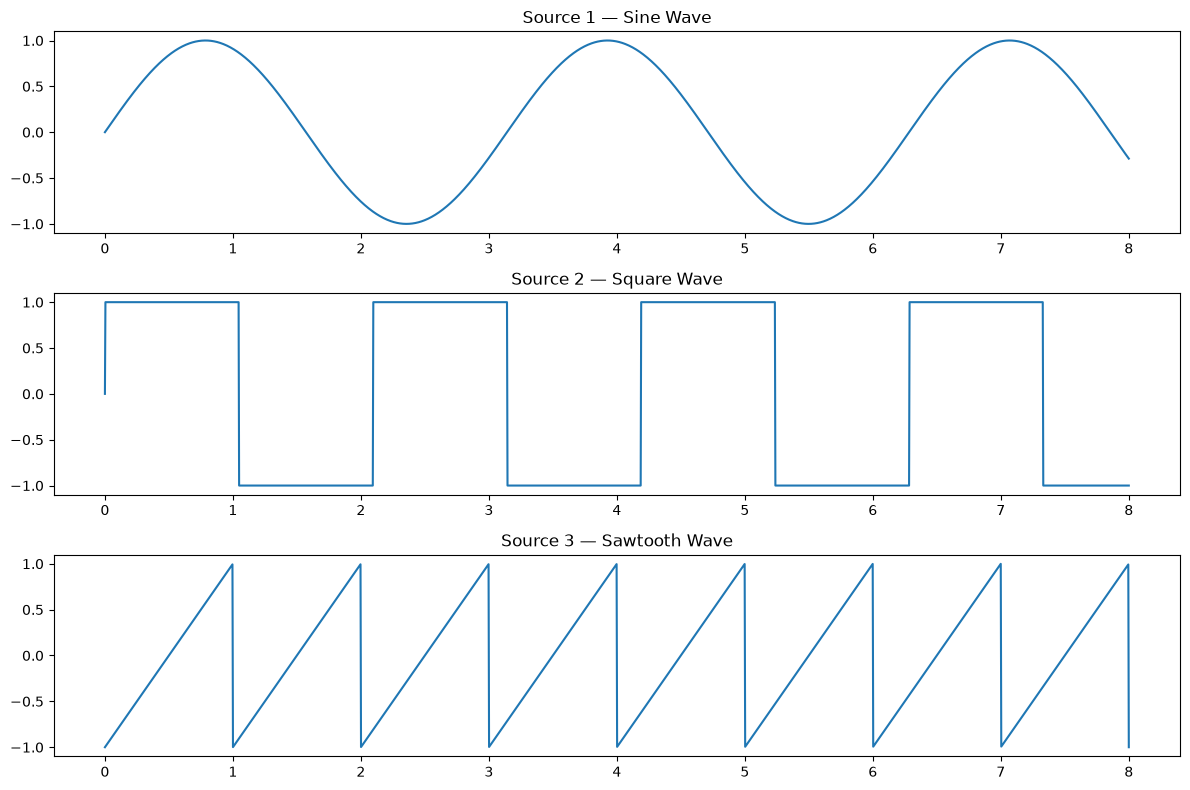

In [5]:
fig, axes = plt.subplots(
    3, 1,                                                # Three separate signal plots
    figsize=(12, 8)
)

axes[0].plot(
    time,
    S[:, 0]                                              # First independent source
)

axes[0].set_title("Source 1 — Sine Wave")


axes[1].plot(
    time,
    S[:, 1]                                              # Second independent source
)

axes[1].set_title("Source 2 — Square Wave")


axes[2].plot(
    time,
    S[:, 2]                                              # Third independent source
)

axes[2].set_title("Source 3 — Sawtooth Wave")


plt.tight_layout()
plt.show()

# Mix the independent sources .

`In the real world, we don't observe these clean source . `

`Instead, ultiple sources become mixed together. `

`We simulate that using a mixing matrix `

In [6]:
A = np.array([
    [1.0, 1.0, 0.5],                                    # How the three sources contribute to observed signal 1
    [0.5, 2.0, 1.0],                                    # How the three sources contribute to observed signal 2
    [1.5, 1.0, 2.0]                                     # How the three sources contribute to observed signal 3
])

`Now create the observed mixtures:`

In [8]:
X = S@ A.T
print("Mixed data shape:", X.shape)

Mixed data shape: (2000, 3)


# Visualize the mixed signals .

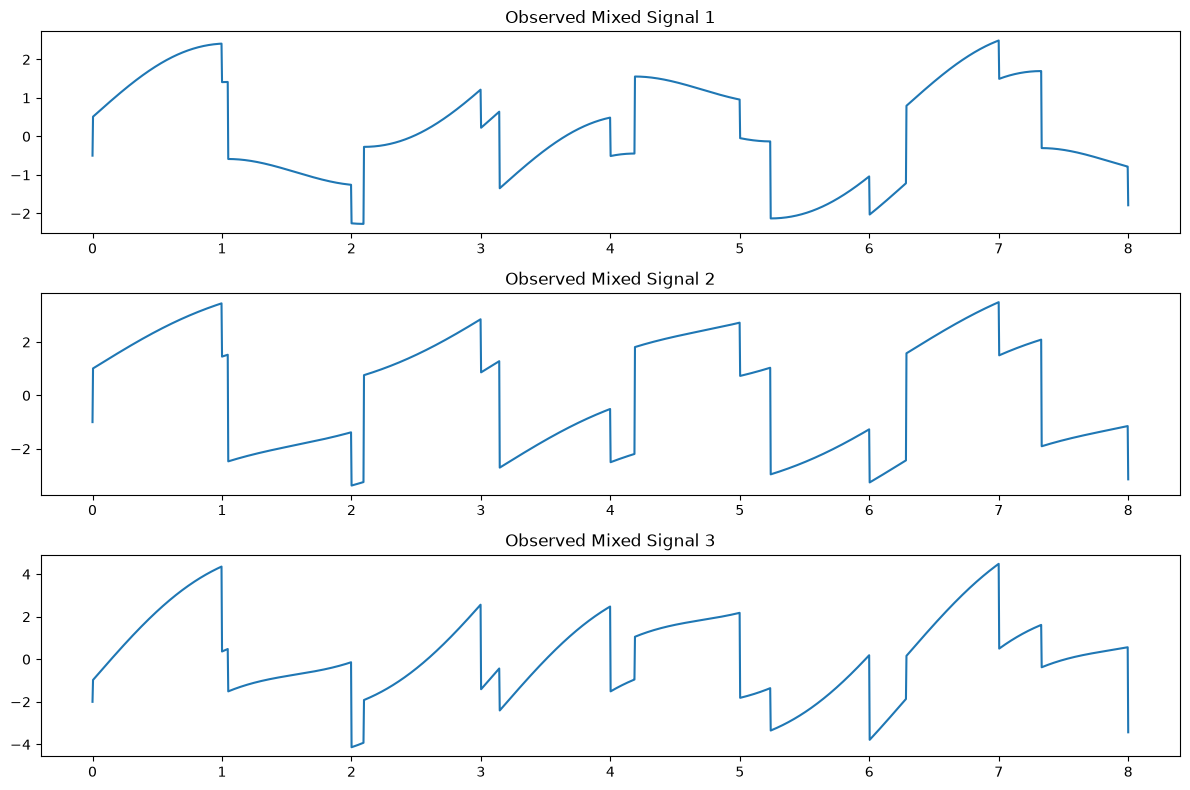

In [10]:
fig, axes = plt.subplots(
    3, 1,                                                # Three observed mixed signals
    figsize=(12, 8)
)

for i, ax in enumerate(axes):

    ax.plot(
        time,
        X[:, i]                                          # One observed mixture
    )

    ax.set_title(f"Observed Mixed Signal {i + 1}")

plt.tight_layout()
plt.show()

# Stadardize the mixed data 

In [11]:
scaler = StandardScaler()                                # Creates the standardization object

X_scaled = scaler.fit_transform(
    X                                                     # Standardize each observed mixed signal
)

# Create the ICA model 


In [12]:
ica = FastICA(
    n_components=3,                                      # Recover three independent components
    random_state=42                                      # Make the result reproducible
)

# Apply ICA 

In [13]:
S_estimated = ica.fit_transform(
    X_scaled                                             # Learn the independent components from the mixed signals
)

print("Original mixed shape:", X_scaled.shape)           # 2000 × 3
print("ICA shape:", S_estimated.shape)                  # 2000 × 3

Original mixed shape: (2000, 3)
ICA shape: (2000, 3)


# Visualize the recovered components. 

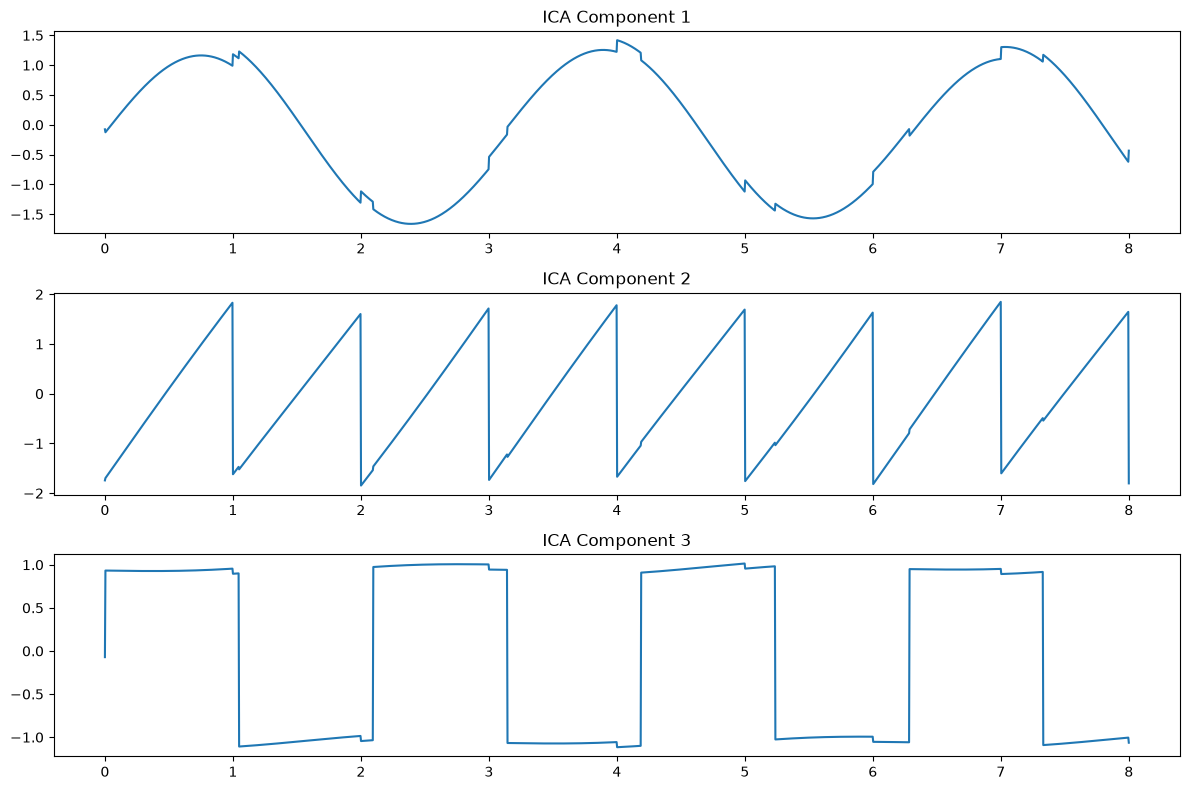

In [14]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 8)
)

for i, ax in enumerate(axes):

    ax.plot(
        time,
        S_estimated[:, i]                                # ICA-recovered independent component
    )

    ax.set_title(f"ICA Component {i + 1}")

plt.tight_layout()
plt.show()

# Compare original and recovered signals 

`Becuase ICA may chnage their order and scale , we will visualize them separately`

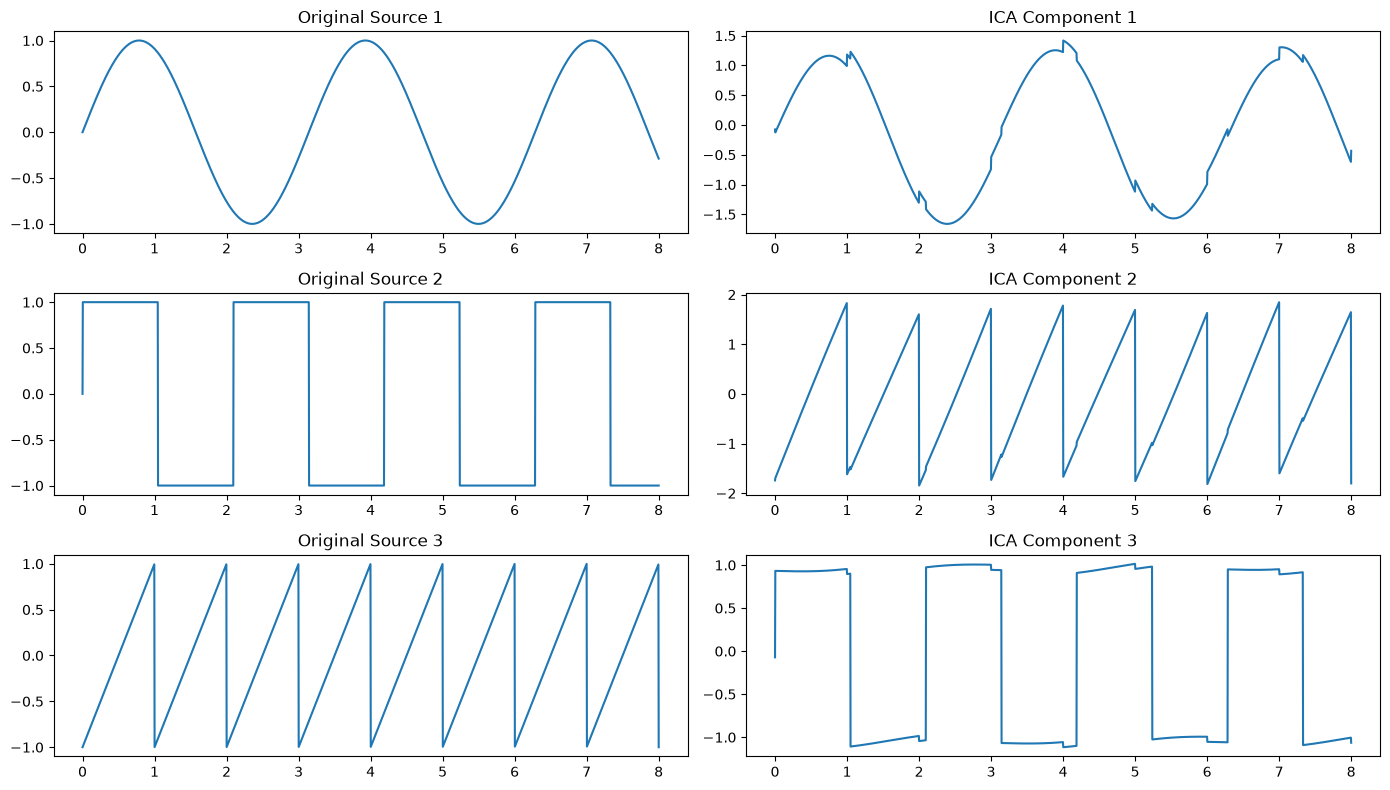

In [15]:
fig, axes = plt.subplots(
    3, 2,
    figsize=(14, 8)
)

for i in range(3):

    axes[i, 0].plot(
        time,
        S[:, i]                                           # Original independent source
    )

    axes[i, 0].set_title(f"Original Source {i + 1}")

    axes[i, 1].plot(
        time,
        S_estimated[:, i]                                 # ICA recovered component
    )

    axes[i, 1].set_title(f"ICA Component {i + 1}")

plt.tight_layout()
plt.show()

# Complete ICA project 

Mixed data shape: (2000, 3)
ICA data shape: (2000, 3)


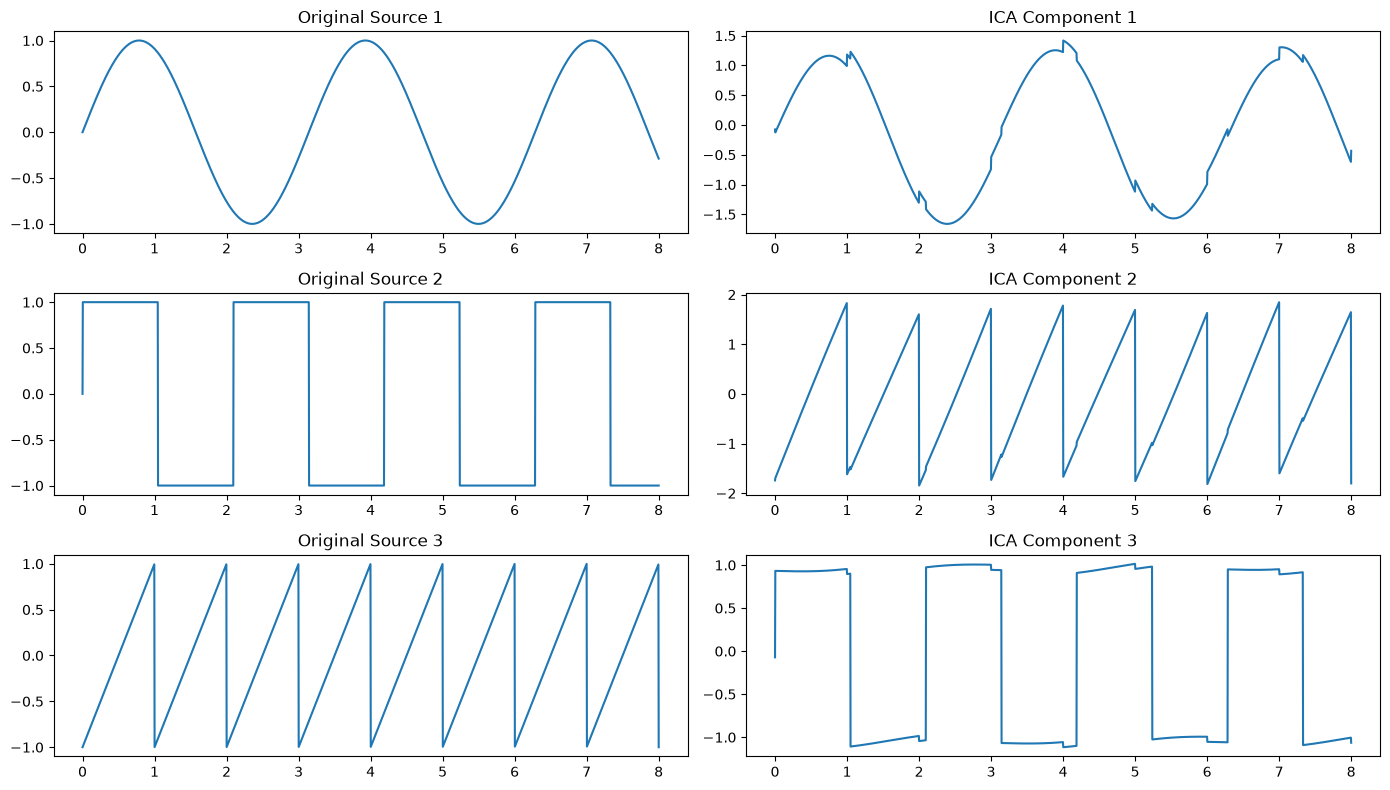

In [16]:
import numpy as np                                      # Numerical calculations
import matplotlib.pyplot as plt                         # Visualization

from sklearn.decomposition import FastICA               # ICA algorithm
from sklearn.preprocessing import StandardScaler        # Feature scaling


np.random.seed(42)                                      # Make signal generation reproducible

n_samples = 2000                                        # Number of observations

time = np.linspace(
    0,
    8,
    n_samples                                            # Create time values for the signals
)


signal_1 = np.sin(
    2 * time                                             # Generate sine-wave source
)

signal_2 = np.sign(
    np.sin(3 * time)                                    # Generate square-wave source
)

signal_3 = (
    2 * (time % 1) - 1                                  # Generate sawtooth-wave source
)


S = np.c_[
    signal_1,                                            # Independent source 1
    signal_2,                                            # Independent source 2
    signal_3                                             # Independent source 3
]


A = np.array([
    [1.0, 1.0, 0.5],                                    # Mixing coefficients for observed signal 1
    [0.5, 2.0, 1.0],                                    # Mixing coefficients for observed signal 2
    [1.5, 1.0, 2.0]                                     # Mixing coefficients for observed signal 3
])


X = S @ A.T                                             # Mix the independent sources


scaler = StandardScaler()                               # Create the scaler

X_scaled = scaler.fit_transform(
    X                                                     # Standardize the mixed signals
)


ica = FastICA(
    n_components=3,                                      # Recover three independent components
    random_state=42                                     # Reproducible ICA result
)


S_estimated = ica.fit_transform(
    X_scaled                                             # Learn and extract independent components
)


print("Mixed data shape:", X.shape)                      # 2000 × 3
print("ICA data shape:", S_estimated.shape)             # 2000 × 3


fig, axes = plt.subplots(
    3,
    2,
    figsize=(14, 8)
)


for i in range(3):

    axes[i, 0].plot(
        time,
        S[:, i]                                          # Original source
    )

    axes[i, 0].set_title(
        f"Original Source {i + 1}"
    )


    axes[i, 1].plot(
        time,
        S_estimated[:, i]                                # ICA recovered component
    )

    axes[i, 1].set_title(
        f"ICA Component {i + 1}"
    )


plt.tight_layout()
plt.show()